
***Blackjack Example 5.1 — Important Terms***

## 1. Objective

Get as close to 21 as possible without exceeding 21.

## 2. State (S)

The current situation is described by three variables:

$$
S = (\text{Player Sum}, \text{Dealer's Visible Card}, \text{Usable Ace})
$$

- **Player's sum:** 12–21
- **Dealer's visible card:** Ace–10
- **Usable Ace:** Yes or No

## 3. Actions (A)

- **Hit:** Take another card.
- **Stick:** Stop taking cards.

## 4. Policy $(π)$

The policy determines which action the player takes:

- If the player's sum is 20 or 21, **stick**.
- Otherwise, **hit**.

## 5. Dealer's Rule

- If the dealer's sum is below 17, **hit**.
- If the dealer's sum is 17 or above, **stick**.

## 6. Reward (R)

The reward depends on the outcome of the game:

\begin{cases}
+1, & \text{Win}\\
-1, & \text{Loss}\\
0, & \text{Draw}
\end{cases}

## 7. Episode

An episode is one complete game, starting from the initial deal and ending when the outcome is determined.

## 8. Return (G)

The return is the total reward obtained during an episode. In this example, it is the final reward because intermediate rewards are zero and the discount factor is one.

$$
\gamma = 1
$$

Therefore,

$$
G = R_{\text{final}}
$$

## 9. State-Value Function (V(s))

The state-value function represents the expected return from a state when the player follows the given policy.

Monte Carlo estimates the state value by averaging the observed returns:

$$
V(s) =
\frac{\text{Sum of Observed Returns}}
{\text{Number of Visits}}
$$

## 10. Monte Carlo Method

The Monte Carlo method simulates many complete games and estimates each state's value by averaging the returns observed after visiting that state.

## 11. Number of States

The state is represented using three variables:

- 10 possible player sums (12–21)
- 10 possible dealer-visible card values (Ace–10)
- 2 possibilities for a usable Ace (Yes or No)

Therefore, the total number of possible states is:

$$ 10 \times 10 \times 2 = 200 $$

## 12. Experiments

The state values are estimated after simulating:

- **10,000 episodes**
- **500,000 episodes**

The estimated state values are then plotted as graphs to compare the results obtained using different numbers of episodes.


1. Play one Blackjack game

In [ ]:

import random
import ipywidgets as widgets
from IPython.display import display
from google.colab import output

output.enable_custom_widget_manager()

# ---------------- GAME LOGIC ----------------

CARD_VALUES = list(range(1, 11))
CARD_PROBS = [1/13] * 9 + [4/13]

def draw_card():
    return random.choices(CARD_VALUES, weights=CARD_PROBS, k=1)[0]

def hand_value(cards):
    total = sum(cards)
    usable_ace = (1 in cards) and (total + 10 <= 21)
    if usable_ace:
        total += 10
    return total, usable_ace

def card_name(card):
    return "A" if card == 1 else str(card)

def cards_html(cards, hidden=False):
    html = ""
    for i, card in enumerate(cards):
        if hidden and i == 1:
            html += """
            <div class="playing-card hidden-card">
                <span>✦</span><small>HIDDEN</small>
            </div>
            """
        else:
            html += f"""
            <div class="playing-card">
                <span>{card_name(card)}</span>
                <small>{'ACE' if card == 1 else 'CARD'}</small>
            </div>
            """
    return html

# ---------------- GAME STATE ----------------

player = []
dealer = []
finished = False
reward = None

# ---------------- UI ----------------

heading = widgets.HTML()
game_display = widgets.HTML()
message = widgets.HTML()

hit_button = widgets.Button(
    description="HIT",
    icon="plus",
    layout=widgets.Layout(width="145px", height="48px")
)

stick_button = widgets.Button(
    description="STICK",
    layout=widgets.Layout(width="145px", height="48px")
)

new_button = widgets.Button(
    description="NEW GAME",
    icon="refresh",
    layout=widgets.Layout(width="165px", height="48px")
)

# ---------------- STYLE ----------------

style = widgets.HTML("""
<style>
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&family=Playfair+Display:wght@600;700;800&display=swap');

.bj-heading {
    font-family: 'Inter', sans-serif;
    padding: 4px 0 12px;
}
.bj-eyebrow {
    font-size: 11px;
    font-weight: 800;
    letter-spacing: 3px;
    color: #9b7130;
}
.bj-main-title {
    font-family: 'Playfair Display', Georgia, serif;
    font-size: 36px;
    line-height: 1.25;
    font-weight: 800;
    color: #174b37 !important;
    margin: 5px 0;
}
.bj-main-title span { color: #bd8732 !important; }
.bj-description {
    color: #53665b;
    font-size: 13px;
    margin-top: 5px;
}

.blackjack-shell {
    font-family: 'Inter', sans-serif;
    background: #111b17;
    color: #f8f6ef;
    border-radius: 18px;
    overflow: hidden;
    border: 1px solid #3c5948;
    box-shadow: 0 12px 30px rgba(20,40,28,.18);
    width: 100%;
    box-sizing: border-box;
}
.bj-header {
    background: linear-gradient(120deg, #183b2c, #24563e);
    padding: 18px 24px;
    border-bottom: 1px solid #52765e;
}
.bj-title {
    font-family: 'Playfair Display', Georgia, serif;
    font-size: 27px;
    font-weight: 800;
    color: #fff7df !important;
}
.bj-title span { color: #ffd879 !important; }
.bj-subtitle {
    color: #d5e6d8;
    font-size: 12px;
    letter-spacing: 1.5px;
    margin-top: 5px;
}

/* NEW: dealer and player side by side */
.bj-table {
    display: grid;
    grid-template-columns: minmax(0, 1fr) minmax(0, 1fr);
    gap: 0;
    background: radial-gradient(ellipse at top, #28694e 0%, #1a4e38 65%, #143b2c 100%);
    padding: 20px 22px;
}
.bj-section {
    padding: 6px 18px 8px 4px;
    min-width: 0;
}
.bj-section + .bj-section {
    border-top: none;
    border-left: 1px solid rgba(255,226,159,.28);
    padding: 6px 4px 8px 22px;
}
.bj-label {
    color: #ffdc8b;
    font-size: 11px;
    font-weight: 800;
    letter-spacing: 2px;
    margin-bottom: 13px;
}
.bj-cards {
    display: flex;
    flex-wrap: wrap;
    gap: 10px;
    min-height: 83px;
    align-items: center;
}
.playing-card {
    flex: 0 0 60px;
    width: 60px;
    height: 82px;
    border-radius: 10px;
    background: #fffdf7;
    box-shadow: 0 5px 10px rgba(0,0,0,.2);
    display: flex;
    flex-direction: column;
    justify-content: center;
    align-items: center;
    border: 1px solid #e3ded0;
    color: #202d26;
    font-weight: 800;
    box-sizing: border-box;
}
.playing-card span { font-size: 27px; line-height: 1.1; }
.playing-card small {
    font-size: 8px;
    letter-spacing: 1px;
    margin-top: 8px;
    color: #697a6d;
}
.hidden-card {
    background: repeating-linear-gradient(45deg, #1c4934, #1c4934 5px, #2c6549 5px, #2c6549 10px);
    color: #ffdc8b;
    border: 2px solid #ffdc8b;
}
.hidden-card small { color: #fff1c9; }
.bj-total {
    color: #f9f8ef;
    font-size: 13px;
    margin-top: 14px;
}
.bj-total strong {
    color: #ffe19a;
    font-size: 22px;
}
.bj-chip {
    display: inline-block;
    padding: 5px 8px;
    margin-top: 6px;
    border-radius: 20px;
    background: #f9e3ad;
    color: #3c321d;
    font-size: 10px;
    font-weight: 800;
}

/* Controls directly under both hands */
.bj-actions {
    background: #17231c;
    padding: 14px 20px;
    border-top: 1px solid #3a5040;
}
.bj-action-label {
    color: #d5e2d7;
    font-family: 'Inter', sans-serif;
    font-size: 11px;
    font-weight: 800;
    letter-spacing: 2px;
    margin-bottom: 10px;
}
.widget-button {
    border: none !important;
    border-radius: 10px !important;
    box-shadow: 0 4px 9px rgba(0,0,0,.15) !important;
    transition: transform .15s ease, filter .15s ease !important;
}
.widget-button:hover:not(:disabled) {
    filter: brightness(1.10) !important;
    transform: translateY(-2px) !important;
}
.widget-button:disabled { opacity: .48 !important; }
.widget-button .widget-label {
    font-family: 'Inter', sans-serif !important;
    font-size: 13px !important;
    font-weight: 800 !important;
    letter-spacing: .7px !important;
}
.bj-tip, .bj-result {
    font-family: 'Inter', sans-serif;
    padding: 13px 16px;
    border-radius: 11px;
    margin-top: 10px;
    font-size: 13px;
    line-height: 1.6;
}
.bj-tip {
    color: #e8f2e9;
    background: #1b3024;
    border: 1px solid #3e6349;
}
.bj-tip strong { color: #ffdc8b; }
.bj-result { font-weight: 500; }
.bj-win {
    background: #e4f6e8;
    border: 1px solid #7dc48c;
    color: #174b2a;
}
.bj-loss {
    background: #ffebeb;
    border: 1px solid #e2a1a1;
    color: #8d2525;
}
.bj-draw {
    background: #fff4d9;
    border: 1px solid #dfc16e;
    color: #75520b;
}

/* On narrow screens, stack the hands so cards don't get squeezed */
@media (max-width: 520px) {
    .bj-table {
        grid-template-columns: minmax(0, 1fr);
        padding: 16px;
    }
    .bj-section {
        padding: 8px 0 18px;
    }
    .bj-section + .bj-section {
        border-left: none;
        border-top: 1px solid rgba(255,226,159,.28);
        padding: 18px 0 8px;
    }
}
</style>
""")

heading.value = """
<div class="bj-heading">
  <div class="bj-eyebrow">CARD TABLE / GAME 01</div>
  <div class="bj-main-title">Blackjack <span>21</span></div>
  <div class="bj-description">
    Beat the dealer. Get close to 21 without going over.
  </div>
</div>
"""

# ---------------- RENDER GAME ----------------

def show_game():
    player_sum, usable_ace = hand_value(player)
    dealer_sum, _ = hand_value(dealer)

    dealer_cards = cards_html(dealer, hidden=not finished)
    dealer_info = (
        f"FINAL TOTAL <strong>{dealer_sum}</strong>"
        if finished else "ONE CARD HIDDEN"
    )

    ace_badge = (
        '<span class="bj-chip">USABLE ACE</span>'
        if usable_ace else ""
    )

    game_display.value = f"""
    <div class="blackjack-shell">
      <div class="bj-header">
        <div class="bj-title">♠ BLACKJACK <span>21</span></div>
        <div class="bj-subtitle">THE CLASSIC CARD GAME</div>
      </div>

      <div class="bj-table">
        <div class="bj-section">
          <div class="bj-label">01 / DEALER</div>
          <div class="bj-cards">{dealer_cards}</div>
          <div class="bj-total">{dealer_info}</div>
        </div>

        <div class="bj-section">
          <div class="bj-label">02 / YOUR HAND</div>
          <div class="bj-cards">{cards_html(player)}</div>
          <div class="bj-total">
            YOUR TOTAL &nbsp; <strong>{player_sum}</strong><br>
            {ace_badge}
          </div>
        </div>
      </div>

      <div class="bj-actions">
        <div class="bj-action-label">MAKE YOUR MOVE</div>
        <div style="color:#d5e2d7;font-size:12px;">
          Hit to draw a card · Stick to end your turn
        </div>
      </div>
    </div>
    """

    hit_button.disabled = finished or player_sum >= 21
    stick_button.disabled = finished

def finish_game(result, explanation):
    global finished, reward
    finished = True
    reward = result

    if result == 1:
        title, css_class, points = "✦ YOU WIN", "bj-win", "+1"
    elif result == -1:
        title, css_class, points = "✕ YOU LOSE", "bj-loss", "−1"
    else:
        title, css_class, points = "＝ DRAW", "bj-draw", "0"

    message.value = f"""
    <div class="bj-result {css_class}">
      <div style="font-size:20px;font-weight:800;margin-bottom:5px;">
        {title} &nbsp; <span style="font-size:14px;">REWARD {points}</span>
      </div>
      <div>{explanation}</div>
    </div>
    """
    show_game()

def start_game():
    global player, dealer, finished, reward

    player = [draw_card(), draw_card()]
    dealer = [draw_card(), draw_card()]
    finished = False
    reward = None
    message.value = ""

    show_game()

    player_sum, _ = hand_value(player)
    dealer_sum, _ = hand_value(dealer)

    player_natural = player_sum == 21
    dealer_natural = dealer_sum == 21

    if player_natural or dealer_natural:
        if player_natural and dealer_natural:
            finish_game(0, "Both player and dealer have a natural blackjack.")
        elif player_natural:
            finish_game(1, "Natural blackjack! You win this round.")
        else:
            finish_game(-1, "The dealer has a natural blackjack.")
    else:
        message.value = """
        <div class="bj-tip">
          <strong>Your turn.</strong> Choose Hit to draw another card,
          or Stick to stand.
        </div>
        """

def hit(_):
    if finished:
        return

    player.append(draw_card())
    player_sum, _ = hand_value(player)

    if player_sum > 21:
        finish_game(-1, "Your total exceeded 21. You busted.")
    elif player_sum == 21:
        stick(None)
    else:
        show_game()
        message.value = f"""
        <div class="bj-tip">
          You drew a card. Your total is
          <strong>{player_sum}</strong>. Hit again or stick?
        </div>
        """

def stick(_):
    if finished:
        return

    dealer_sum, _ = hand_value(dealer)

    while dealer_sum < 17:
        dealer.append(draw_card())
        dealer_sum, _ = hand_value(dealer)

    player_sum, _ = hand_value(player)

    if dealer_sum > 21:
        finish_game(1, "The dealer busted by exceeding 21.")
    elif player_sum > dealer_sum:
        finish_game(1, "Your final total is higher than the dealer's.")
    elif player_sum < dealer_sum:
        finish_game(-1, "The dealer's final total is higher than yours.")
    else:
        finish_game(0, "Both hands have the same total.")

def new_game(_):
    start_game()

# ---------------- BUTTON COLORS ----------------

hit_button.style.button_color = "#2878D0"
hit_button.style.text_color = "#FFFFFF"
hit_button.style.font_weight = "bold"

stick_button.style.button_color = "#7651A8"
stick_button.style.text_color = "#FFFFFF"
stick_button.style.font_weight = "bold"

new_button.style.button_color = "#24764F"
new_button.style.text_color = "#FFFFFF"
new_button.style.font_weight = "bold"

hit_button.on_click(hit)
stick_button.on_click(stick)
new_button.on_click(new_game)

buttons = widgets.HBox(
    [hit_button, stick_button, new_button],
    layout=widgets.Layout(
        gap="12px",
        flex_flow="row wrap",
        margin="10px 0"
    )
)

# ---------------- DISPLAY ----------------

display(style)
display(heading)
display(game_display)
display(buttons)
display(message)

start_game()


HTML(value="\n<style>\n@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&fa…

HTML(value='\n<div class="bj-heading">\n  <div class="bj-eyebrow">CARD TABLE / GAME 01</div>\n  <div class="bj…

HTML(value='')

HTML(value='')

2. Run Monte Carlo experiments Every Visit


RESULTS AFTER 10,000 EPISODES
Total games : 10,000
Wins        : 2,870 (28.70%)
Losses      : 6,585 (65.85%)
Draws       : 545 (5.45%)

STATE-BY-STATE OUTCOME COUNTS
State value = (Wins - Losses) / Visits
Zero-visit states have no estimated value.

 Usable Ace  Player Sum  Dealer Showing  Visits  Wins  Losses  Draws State Value
      False          12               1      62     8      51      3     -0.6935
      False          12               2      93    16      76      1     -0.6452
      False          12               3      92    18      72      2     -0.5870
      False          12               4      78    15      60      3     -0.5769
      False          12               5     102    32      66      4     -0.3333
      False          12               6      74    20      49      5     -0.3919
      False          12               7     103    27      75      1     -0.4660
      False          12               8     108    34      71      3     -0.3426
      False          

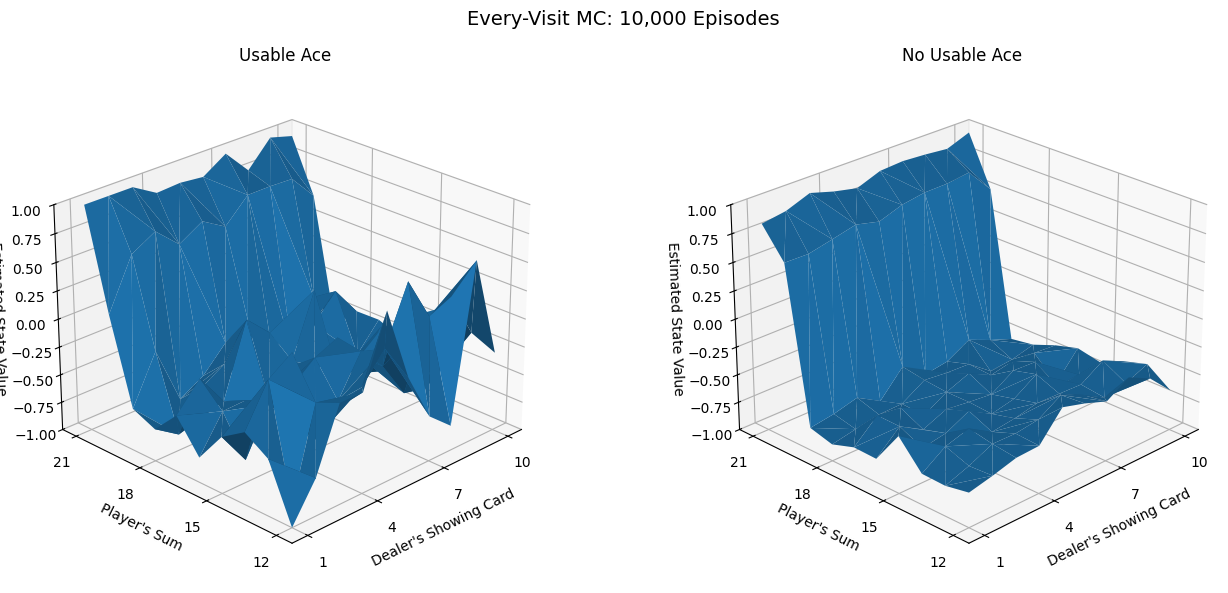


RESULTS AFTER 50,000 EPISODES
Total games : 50,000
Wins        : 14,859 (29.72%)
Losses      : 32,626 (65.25%)
Draws       : 2,515 (5.03%)

STATE-BY-STATE OUTCOME COUNTS
State value = (Wins - Losses) / Visits
Zero-visit states have no estimated value.

 Usable Ace  Player Sum  Dealer Showing  Visits  Wins  Losses  Draws State Value
      False          12               1     307    52     243     12     -0.6221
      False          12               2     413    82     317     14     -0.5690
      False          12               3     467    84     368     15     -0.6081
      False          12               4     491    98     382     11     -0.5784
      False          12               5     461    98     351     12     -0.5488
      False          12               6     485   110     366      9     -0.5278
      False          12               7     408   108     288     12     -0.4412
      False          12               8     454   117     331      6     -0.4714
      False      

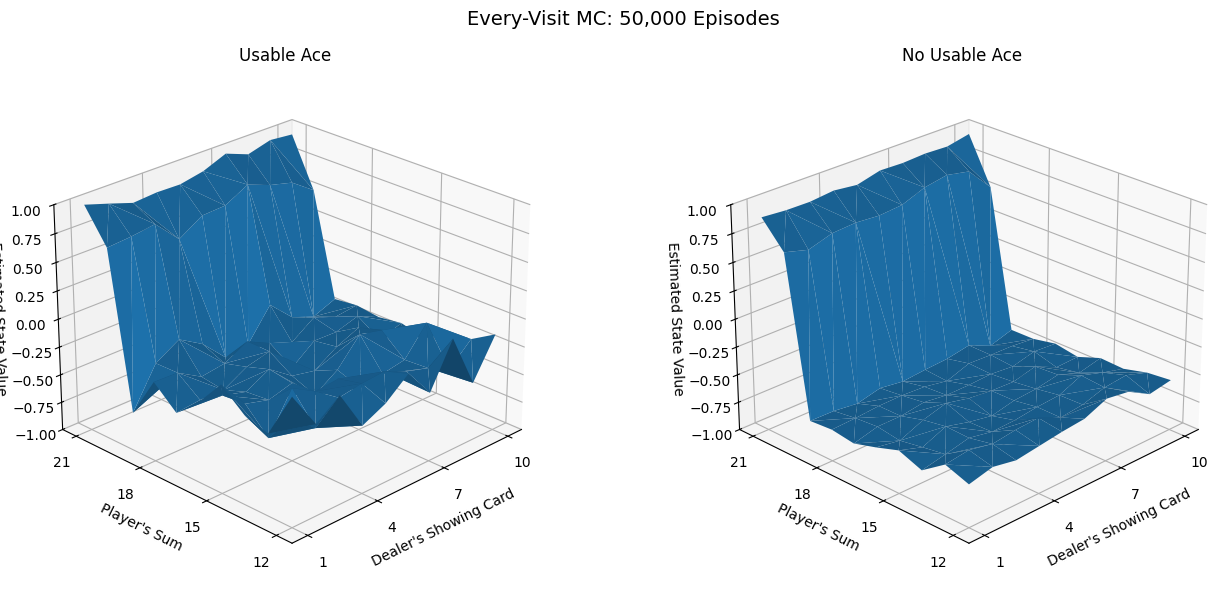


RESULTS AFTER 10,000 EPISODES
Total games : 10,000
Wins        : 3,051 (30.51%)
Losses      : 6,430 (64.30%)
Draws       : 519 (5.19%)

STATE-BY-STATE OUTCOME COUNTS
State value = (Wins - Losses) / Visits
Zero-visit states have no estimated value.

 Usable Ace  Player Sum  Dealer Showing  Visits  Wins  Losses  Draws State Value
      False          12               1      68    12      52      4     -0.5882
      False          12               2      94    24      67      3     -0.4574
      False          12               3      81    20      60      1     -0.4938
      False          12               4      96    24      69      3     -0.4688
      False          12               5      87    18      67      2     -0.5632
      False          12               6     101    25      72      4     -0.4653
      False          12               7     101    30      69      2     -0.3861
      False          12               8      91    24      62      5     -0.4176
      False          

In [4]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# --------------------------------------------------
# 1. INITIAL SETTINGS
# --------------------------------------------------
rng = np.random.default_rng(42)

CARD_VALUES = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
CARD_PROBS = np.array([1/13] * 9 + [4/13])

def draw_card():
    return int(rng.choice(CARD_VALUES, p=CARD_PROBS))

def hand_value(cards):
    total = sum(cards)
    usable_ace = (1 in cards) and (total + 10 <= 21)

    if usable_ace:
        total += 10

    return total, usable_ace


# --------------------------------------------------
# 2. PLAY ONE COMPLETE BLACKJACK GAME
# --------------------------------------------------
def play_episode():
    player = [draw_card(), draw_card()]
    dealer = [draw_card(), draw_card()]

    dealer_showing = dealer[0]
    player_sum, _ = hand_value(player)
    dealer_sum, _ = hand_value(dealer)

    # Handle natural blackjack
    player_natural = player_sum == 21
    dealer_natural = dealer_sum == 21

    if player_natural or dealer_natural:
        if player_natural and dealer_natural:
            return 0, []
        elif player_natural:
            return 1, []
        else:
            return -1, []

    visited = []

    # Player's fixed policy:
    # Hit below 20; stick on 20 or 21
    while True:
        player_sum, usable_ace = hand_value(player)

        # Record states with player sum 12–21
        if 12 <= player_sum <= 21:
            visited.append(
                (player_sum, dealer_showing, usable_ace)
            )

        if player_sum >= 20:
            break

        player.append(draw_card())
        player_sum, _ = hand_value(player)

        if player_sum > 21:
            return -1, visited

    # Dealer hits below 17
    while True:
        dealer_sum, _ = hand_value(dealer)

        if dealer_sum >= 17:
            break

        dealer.append(draw_card())
        dealer_sum, _ = hand_value(dealer)

        if dealer_sum > 21:
            return 1, visited

    # Compare final scores
    player_sum, _ = hand_value(player)

    if player_sum > dealer_sum:
        return 1, visited
    elif player_sum < dealer_sum:
        return -1, visited
    else:
        return 0, visited


# --------------------------------------------------
# 3. EVERY-VISIT MONTE CARLO PREDICTION
# --------------------------------------------------
def mc_prediction(n_episodes):

    # Store outcome counts for all 200 states
    stats = {
        (usable, player, dealer): {
            "Win": 0,
            "Loss": 0,
            "Draw": 0,
            "Visits": 0
        }
        for usable in [False, True]
        for player in range(12, 22)
        for dealer in range(1, 11)
    }

    total_wins = 0
    total_losses = 0
    total_draws = 0

    for _ in range(n_episodes):
        reward, states = play_episode()

        # Count overall game outcomes
        if reward == 1:
            total_wins += 1
        elif reward == -1:
            total_losses += 1
        else:
            total_draws += 1

        # EVERY-VISIT MC:
        # Process every occurrence, including repetitions
        for player, dealer, usable in states:
            key = (usable, player, dealer)

            stats[key]["Visits"] += 1

            if reward == 1:
                stats[key]["Win"] += 1
            elif reward == -1:
                stats[key]["Loss"] += 1
            else:
                stats[key]["Draw"] += 1

    # Calculate state values and create a report
    rows = []
    values = {}

    for key, outcome in stats.items():
        usable, player, dealer = key

        visits = outcome["Visits"]

        # Expected return = average final reward
        if visits > 0:
            value = (
                outcome["Win"] - outcome["Loss"]
            ) / visits
        else:
            value = np.nan

        values[key] = value

        rows.append({
            "Usable Ace": usable,
            "Player Sum": player,
            "Dealer Showing": dealer,
            "Visits": visits,
            "Wins": outcome["Win"],
            "Losses": outcome["Loss"],
            "Draws": outcome["Draw"],
            "State Value": value
        })

    report = pd.DataFrame(rows)

    # Print overall results
    print("\n" + "=" * 75)
    print(f"RESULTS AFTER {n_episodes:,} EPISODES")
    print("=" * 75)
    print(f"Total games : {n_episodes:,}")
    print(f"Wins        : {total_wins:,} "
          f"({total_wins / n_episodes:.2%})")
    print(f"Losses      : {total_losses:,} "
          f"({total_losses / n_episodes:.2%})")
    print(f"Draws       : {total_draws:,} "
          f"({total_draws / n_episodes:.2%})")

    # Print outcome counts for every state
    print("\nSTATE-BY-STATE OUTCOME COUNTS")
    print("State value = (Wins - Losses) / Visits")
    print("Zero-visit states have no estimated value.\n")

    print(report.to_string(
        index=False,
        formatters={
            "State Value": lambda x: (
                "N/A" if pd.isna(x) else f"{x:.4f}"
            )
        }
    ))

    return values, report


# --------------------------------------------------
# 4. PLOT THE STATE-VALUE GRAPHS
# --------------------------------------------------
def plot_values(values, title):

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 6),
        subplot_kw={"projection": "3d"}
    )

    for ax, usable in zip(axes, [True, False]):
        x, y, z = [], [], []

        for player in range(12, 22):
            for dealer in range(1, 11):
                value = values[(usable, player, dealer)]

                if np.isfinite(value):
                    x.append(dealer)
                    y.append(player)
                    z.append(value)

        if len(x) >= 3:
            ax.plot_trisurf(
                x, y, z,
                linewidth=0.2,
                antialiased=True
            )

        ax.set_title(
            "Usable Ace" if usable else "No Usable Ace"
        )
        ax.set_xlabel("Dealer's Showing Card")
        ax.set_ylabel("Player's Sum")
        ax.set_zlabel("Estimated State Value")
        ax.set_zlim(-1, 1)
        ax.set_xticks([1, 4, 7, 10])
        ax.set_yticks([12, 15, 18, 21])
        ax.view_init(elev=25, azim=-135)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# 5. RUN FOR 10,000 EPISODES
# --------------------------------------------------
values_10000, report_10000 = mc_prediction(10_000)
plot_values(values_10000, "Every-Visit MC: 10,000 Episodes")


# --------------------------------------------------
# 6. RUN FOR 50,000 EPISODES
# --------------------------------------------------
values_50000, report_50000 = mc_prediction(50_000)
plot_values(values_50000, "Every-Visit MC: 50,000 Episodes")

values_10000_every, report_10000_every = mc_prediction(10_000)
values_50000_every, report_50000_every = mc_prediction(50_000)


Run Monte Carlo experiments Every Visit


RESULTS AFTER 10,000 EPISODES
Total games : 10,000
Wins        : 2,870 (28.70%)
Losses      : 6,585 (65.85%)
Draws       : 545 (5.45%)

STATE-BY-STATE OUTCOME COUNTS
State value = (Wins - Losses) / Visits
Zero-visit states have no estimated value.

 Usable Ace  Player Sum  Dealer Showing  Visits  Wins  Losses  Draws State Value
      False          12               1      62     8      51      3     -0.6935
      False          12               2      93    16      76      1     -0.6452
      False          12               3      92    18      72      2     -0.5870
      False          12               4      78    15      60      3     -0.5769
      False          12               5     102    32      66      4     -0.3333
      False          12               6      74    20      49      5     -0.3919
      False          12               7     103    27      75      1     -0.4660
      False          12               8     108    34      71      3     -0.3426
      False          

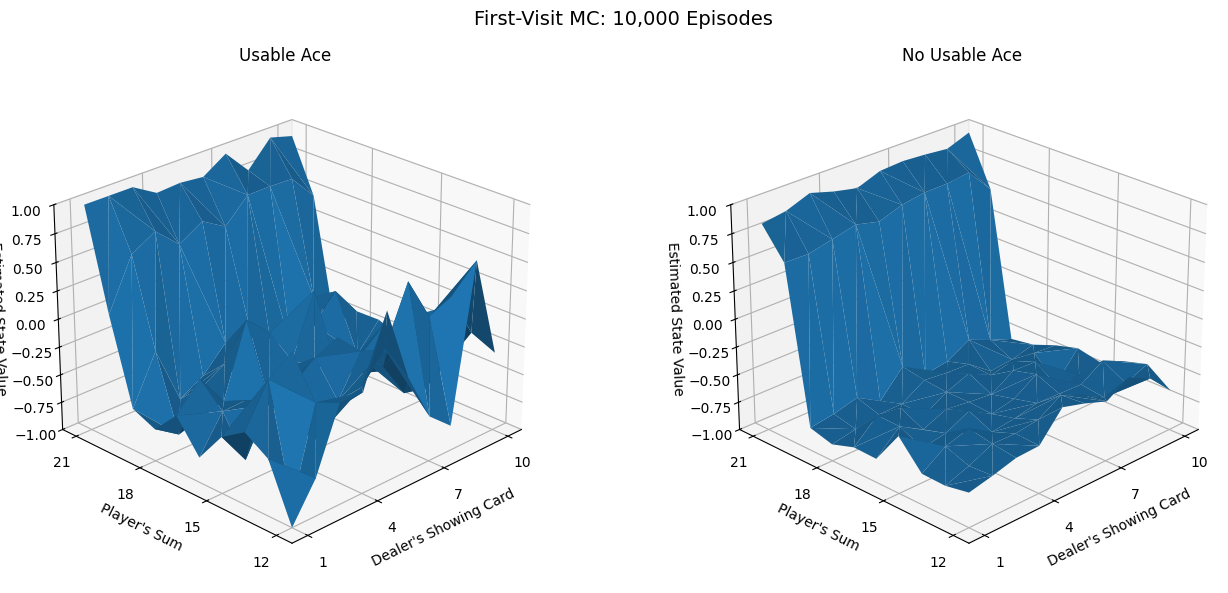


RESULTS AFTER 50,000 EPISODES
Total games : 50,000
Wins        : 14,859 (29.72%)
Losses      : 32,626 (65.25%)
Draws       : 2,515 (5.03%)

STATE-BY-STATE OUTCOME COUNTS
State value = (Wins - Losses) / Visits
Zero-visit states have no estimated value.

 Usable Ace  Player Sum  Dealer Showing  Visits  Wins  Losses  Draws State Value
      False          12               1     307    52     243     12     -0.6221
      False          12               2     413    82     317     14     -0.5690
      False          12               3     467    84     368     15     -0.6081
      False          12               4     491    98     382     11     -0.5784
      False          12               5     461    98     351     12     -0.5488
      False          12               6     485   110     366      9     -0.5278
      False          12               7     408   108     288     12     -0.4412
      False          12               8     454   117     331      6     -0.4714
      False      

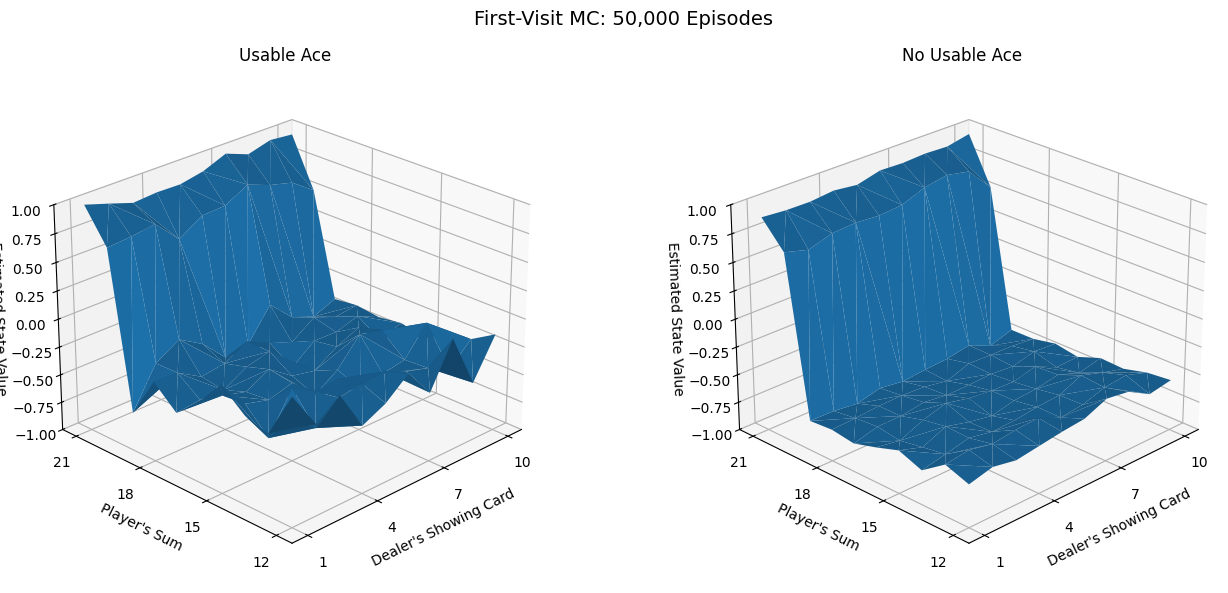


RESULTS AFTER 10,000 EPISODES
Total games : 10,000
Wins        : 3,051 (30.51%)
Losses      : 6,430 (64.30%)
Draws       : 519 (5.19%)

STATE-BY-STATE OUTCOME COUNTS
State value = (Wins - Losses) / Visits
Zero-visit states have no estimated value.

 Usable Ace  Player Sum  Dealer Showing  Visits  Wins  Losses  Draws State Value
      False          12               1      68    12      52      4     -0.5882
      False          12               2      94    24      67      3     -0.4574
      False          12               3      81    20      60      1     -0.4938
      False          12               4      96    24      69      3     -0.4688
      False          12               5      87    18      67      2     -0.5632
      False          12               6     101    25      72      4     -0.4653
      False          12               7     101    30      69      2     -0.3861
      False          12               8      91    24      62      5     -0.4176
      False          

In [5]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# --------------------------------------------------
# 1. INITIAL SETTINGS
# --------------------------------------------------
rng = np.random.default_rng(42)

CARD_VALUES = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
CARD_PROBS = np.array([1/13] * 9 + [4/13])


def draw_card():
    return int(rng.choice(CARD_VALUES, p=CARD_PROBS))


def hand_value(cards):
    total = sum(cards)
    usable_ace = (1 in cards) and (total + 10 <= 21)

    if usable_ace:
        total += 10

    return total, usable_ace


# --------------------------------------------------
# 2. PLAY ONE COMPLETE BLACKJACK GAME
# --------------------------------------------------
def play_episode():
    player = [draw_card(), draw_card()]
    dealer = [draw_card(), draw_card()]

    dealer_showing = dealer[0]
    player_sum, _ = hand_value(player)
    dealer_sum, _ = hand_value(dealer)

    # Handle natural blackjack
    player_natural = player_sum == 21
    dealer_natural = dealer_sum == 21

    if player_natural or dealer_natural:
        if player_natural and dealer_natural:
            return 0, []
        elif player_natural:
            return 1, []
        else:
            return -1, []

    visited = []

    # Fixed policy: hit below 20; stick on 20 or 21
    while True:
        player_sum, usable_ace = hand_value(player)

        if 12 <= player_sum <= 21:
            visited.append(
                (player_sum, dealer_showing, usable_ace)
            )

        if player_sum >= 20:
            break

        player.append(draw_card())
        player_sum, _ = hand_value(player)

        if player_sum > 21:
            return -1, visited

    # Dealer hits below 17
    while True:
        dealer_sum, _ = hand_value(dealer)

        if dealer_sum >= 17:
            break

        dealer.append(draw_card())
        dealer_sum, _ = hand_value(dealer)

        if dealer_sum > 21:
            return 1, visited

    # Compare final scores
    player_sum, _ = hand_value(player)

    if player_sum > dealer_sum:
        return 1, visited
    elif player_sum < dealer_sum:
        return -1, visited
    else:
        return 0, visited


# --------------------------------------------------
# 3. FIRST-VISIT MONTE CARLO PREDICTION
# --------------------------------------------------
def mc_prediction(n_episodes):

    stats = {
        (usable, player, dealer): {
            "Win": 0,
            "Loss": 0,
            "Draw": 0,
            "Visits": 0
        }
        for usable in [False, True]
        for player in range(12, 22)
        for dealer in range(1, 11)
    }

    total_wins = 0
    total_losses = 0
    total_draws = 0

    for _ in range(n_episodes):
        reward, states = play_episode()

        # Count overall game outcomes
        if reward == 1:
            total_wins += 1
        elif reward == -1:
            total_losses += 1
        else:
            total_draws += 1

        # FIRST-VISIT MC:
        # Count each distinct state only once per episode
        first_visit_states = set(states)

        for player, dealer, usable in first_visit_states:
            key = (usable, player, dealer)

            stats[key]["Visits"] += 1

            if reward == 1:
                stats[key]["Win"] += 1
            elif reward == -1:
                stats[key]["Loss"] += 1
            else:
                stats[key]["Draw"] += 1

    # Calculate state values and build report
    rows = []
    values = {}

    for key, outcome in stats.items():
        usable, player, dealer = key
        visits = outcome["Visits"]

        if visits > 0:
            value = (
                outcome["Win"] - outcome["Loss"]
            ) / visits
        else:
            value = np.nan

        values[key] = value

        rows.append({
            "Usable Ace": usable,
            "Player Sum": player,
            "Dealer Showing": dealer,
            "Visits": visits,
            "Wins": outcome["Win"],
            "Losses": outcome["Loss"],
            "Draws": outcome["Draw"],
            "State Value": value
        })

    report = pd.DataFrame(rows)

    # Print overall results
    print("\n" + "=" * 75)
    print(f"RESULTS AFTER {n_episodes:,} EPISODES")
    print("=" * 75)
    print(f"Total games : {n_episodes:,}")
    print(f"Wins        : {total_wins:,} "
          f"({total_wins / n_episodes:.2%})")
    print(f"Losses      : {total_losses:,} "
          f"({total_losses / n_episodes:.2%})")
    print(f"Draws       : {total_draws:,} "
          f"({total_draws / n_episodes:.2%})")

    print("\nSTATE-BY-STATE OUTCOME COUNTS")
    print("State value = (Wins - Losses) / Visits")
    print("Zero-visit states have no estimated value.\n")

    print(report.to_string(
        index=False,
        formatters={
            "State Value": lambda x: (
                "N/A" if pd.isna(x) else f"{x:.4f}"
            )
        }
    ))

    return values, report


# --------------------------------------------------
# 4. PLOT STATE-VALUE GRAPHS
# --------------------------------------------------
def plot_values(values, title):

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 6),
        subplot_kw={"projection": "3d"}
    )

    for ax, usable in zip(axes, [True, False]):
        x, y, z = [], [], []

        for player in range(12, 22):
            for dealer in range(1, 11):
                value = values[(usable, player, dealer)]

                if np.isfinite(value):
                    x.append(dealer)
                    y.append(player)
                    z.append(value)

        if len(x) >= 3:
            ax.plot_trisurf(
                x, y, z,
                linewidth=0.2,
                antialiased=True
            )

        ax.set_title(
            "Usable Ace" if usable else "No Usable Ace"
        )
        ax.set_xlabel("Dealer's Showing Card")
        ax.set_ylabel("Player's Sum")
        ax.set_zlabel("Estimated State Value")
        ax.set_zlim(-1, 1)
        ax.set_xticks([1, 4, 7, 10])
        ax.set_yticks([12, 15, 18, 21])
        ax.view_init(elev=25, azim=-135)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# 5. RUN FOR 10,000 EPISODES
# --------------------------------------------------
values_10000, report_10000 = mc_prediction(10_000)

plot_values(
    values_10000,
    "First-Visit MC: 10,000 Episodes"
)


# --------------------------------------------------
# 6. RUN FOR 50,000 EPISODES
# --------------------------------------------------
values_50000, report_50000 = mc_prediction(50_000)

plot_values(
    values_50000,
    "First-Visit MC: 50,000 Episodes"
)
values_10000_first, report_10000_first_visit = mc_prediction(10_000)
values_50000_first, report_50000_first_visit = mc_prediction(50_000)

Difference Between Every Visit MC and First Vist MC State Values

In [6]:
comparison = report_10000.merge(
    report_10000_first_visit,
    on=["Usable Ace", "Player Sum", "Dealer Showing"],
    suffixes=("_Every", "_First")
)

print(comparison[
    [
        "Usable Ace", "Player Sum", "Dealer Showing",
        "Visits_Every", "Visits_First",
        "State Value_Every", "State Value_First"
    ]
].to_string(index=False))

 Usable Ace  Player Sum  Dealer Showing  Visits_Every  Visits_First  State Value_Every  State Value_First
      False          12               1            62            68          -0.693548          -0.588235
      False          12               2            93            94          -0.645161          -0.457447
      False          12               3            92            81          -0.586957          -0.493827
      False          12               4            78            96          -0.576923          -0.468750
      False          12               5           102            87          -0.333333          -0.563218
      False          12               6            74           101          -0.391892          -0.465347
      False          12               7           103           101          -0.466019          -0.386139
      False          12               8           108            91          -0.342593          -0.417582
      False          12               9       